# Week 6 - Test the saved full data models
I trained Logistic Regression, Random Forest, and XGBoost on all **6,983,917 records from 2005–2020** and saved the models. This notebook loads those saved files and tests each model separately on 2021, 2022, 2023, and 2024.

The model settings and threshold 0.20 were selected. They stay fixed during testing. The preprocessing has 19 input predictors and 89 encoded columns.

In [24]:
import zipfile
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import xgboost
from IPython.display import display
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.metrics import roc_auc_score, precision_recall_curve, auc
from sklearn.metrics import confusion_matrix
from sklearn.calibration import CalibrationDisplay


zip_path = Path("csv.zip")
model_folder = Path(".")

files = {}
with zipfile.ZipFile(zip_path) as z:
    for name in z.namelist():
        if name.lower().endswith(".csv"):
            files[Path(name).name] = name

## Load the saved models
The preprocessor keeps the medians, scaling, and categories learned from the training data. I use the same fitted preprocessor for every test year. The threshold file keeps the classification threshold chosen earlier.

In [25]:
# Load the files saved after full-data training
preprocessor = joblib.load(model_folder / "final_preprocessor.joblib")
threshold = joblib.load(model_folder / "final_threshold.joblib")
lr_model = joblib.load(model_folder / "final_logistic_regression.joblib")
rf_model = joblib.load(model_folder / "final_random_forest.joblib")
xgb_model = joblib.load(model_folder / "final_xgboost.joblib")

# Keep the models together so the same test steps can be applied to each one
models = {
    "Logistic Regression": lr_model,
    "Random Forest": rf_model,
    "XGBoost": xgb_model
}

print("All five saved files loaded successfully.")
print("Saved threshold:", threshold)
print("Encoded columns:", len(preprocessor.get_feature_names_out()))

All five saved files loaded successfully.
Saved threshold: 0.2
Encoded columns: 89


## Check features are the same

In [26]:
# Use the same predictors and target definition as Week 5
numeric_features = [
    "bmi_00",
    "mental_health_days_00",
    "physical_health_days_00"
]

categorical_features = [
    "age_00", "sex_00", "race_00", "marital_status_00", "education_00",
    "income", "gen_health_00", "exercise_00", "smoked_100_cigarettes_00",
    "drinks_alcohol_00", "had_stroke_00", "had_heart_attack_00",
    "had_coronary_heart_disease_00", "cost_barrier_00",
    "l_checkup_00", "has_personal_doctor_00"
]

predictor_columns = numeric_features + categorical_features

target_map = {
    "Diabetic": 1,
    "Non-diabetic": 0,
    "Pre-diabetic": 0
}

# Check the column order before transforming test data
assert list(preprocessor.feature_names_in_) == predictor_columns
print("Predictor order matches the saved preprocessor.")

Predictor order matches the saved preprocessor.


## Load and clean test years
Newer income codes 8–11 are combined into income group 8. BMI values outside 12–99.99 and health-day values outside 0–30 are changed to missing values.

Records with missing predictors are kept. The saved preprocessor will handle them. A record needs a known diabetes target for evaluation. The function also stops if an unexpected target label is found.

In [27]:
def load_year(year):
    # Choose the income column for this year
    if year <= 2020:
        income_column = "income_00"
        income_maximum = 8
    else:
        income_column = "income_01"
        income_maximum = 11

    source_columns = numeric_features + categorical_features
    source_columns.remove("income")
    source_columns.append(income_column)
    source_columns.append("diabetes")

    annual_name = "DATASET_" + str(year) + ".csv"
    with zipfile.ZipFile(zip_path) as z:
        with z.open(files[annual_name]) as f:
            raw = pd.read_csv(f, usecols=source_columns, low_memory=False)

    # Keep all records with one of the expected target labels
    original_count = len(raw)
    missing_target_count = int(raw["diabetes"].isna().sum())
    mapped_target = raw["diabetes"].map(target_map)
    unexpected_target = raw["diabetes"].notna() & mapped_target.isna()
    if unexpected_target.any():
        unexpected_labels = raw.loc[unexpected_target, "diabetes"].unique()
        raise ValueError("Unexpected diabetes labels: " + str(unexpected_labels))

    clean = raw.loc[mapped_target.notna()].copy()
    clean["target"] = mapped_target.loc[mapped_target.notna()].astype("int8")
    del raw, mapped_target

    # Match income groups across years
    income = pd.to_numeric(clean[income_column], errors="coerce")
    valid_income = income.isin(range(1, income_maximum + 1))
    income = income.where(valid_income)
    clean["income"] = income.replace({9: 8, 10: 8, 11: 8})

    # Keep records with invalid predictors, but set those values to missing
    bmi = pd.to_numeric(clean["bmi_00"], errors="coerce")
    invalid_bmi = bmi.notna() & ~bmi.between(12.00, 99.99)
    clean["bmi_00"] = bmi.where(bmi.between(12.00, 99.99))
    for feature in ["mental_health_days_00", "physical_health_days_00"]:
        values = pd.to_numeric(clean[feature], errors="coerce")
        clean[feature] = values.where(values.between(0, 30))

    clean = clean[predictor_columns + ["target"]].copy()
    for feature in categorical_features:
        labels = clean[feature].astype("string")
        labels = labels.str.replace(r"\.0$", "", regex=True)
        labels = labels.fillna("<missing>")
        clean[feature] = labels.astype(str)
    for feature in numeric_features:
        clean[feature] = clean[feature].astype("float32")

    audit = {
        "year": year,
        "original_rows": original_count,
        "missing_target_rows": missing_target_count,
        "used_rows": len(clean),
        "positive_rows": int(clean["target"].sum()),
        "bmi_changed_to_missing": int(invalid_bmi.sum())
    }
    return clean, audit

## Test each year separately
I apply `transform` to the test inputs and get scores from the saved models. A score of 0.20 or higher is classified as diabetes.

Precision, recall, and F1 use this threshold. ROC-AUC and PR-AUC use the probability scores. PR-AUC uses the trapezoidal area, as in the earlier weeks. Calibration points near the diagonal show closer agreement between scores and observed diabetes proportions.

Testing 2021 — records: 437250


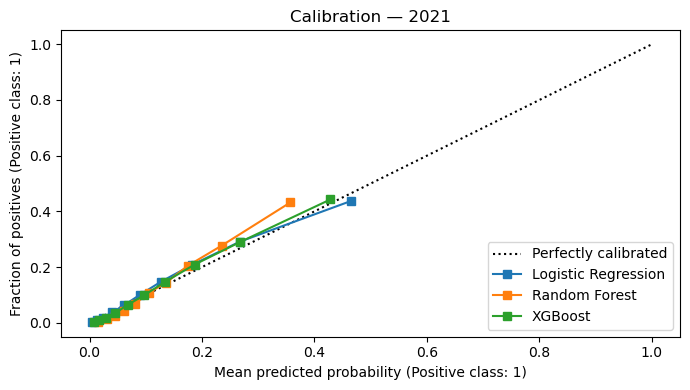

Testing 2022 — records: 442670


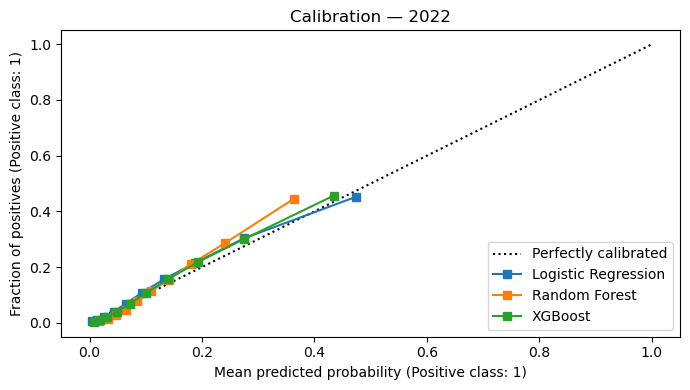

Testing 2023 — records: 431746


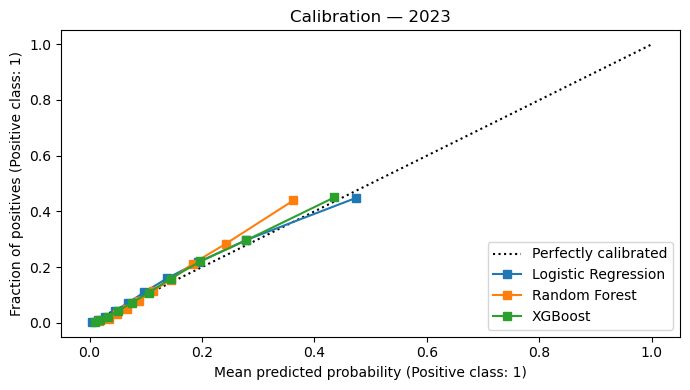

Testing 2024 — records: 454774


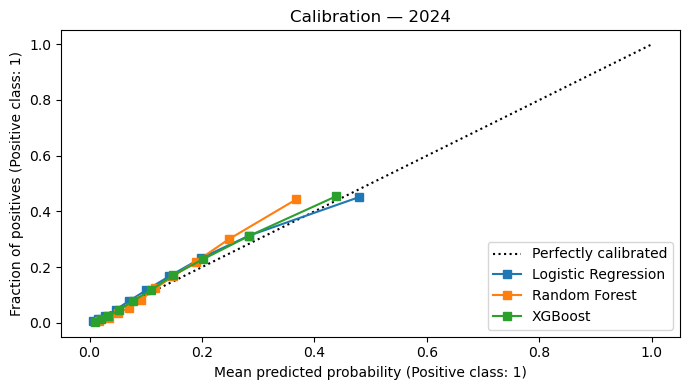

In [28]:
result_rows = []
error_rows = []
test_rows = []

for year in range(2021, 2025):
    test_data, audit = load_year(year)
    test_rows.append(audit)
    X_test = test_data[predictor_columns]
    y_test = test_data["target"]

    # Apply the saved preprocessing; do not learn anything from test inputs
    X_test_ready = preprocessor.transform(X_test)
    X_test_ready = X_test_ready.astype("float32")
    print("Testing", year, "— records:", len(y_test), flush=True)

    figure, calibration_axis = plt.subplots(figsize=(7, 4))
    for name, model in models.items():
        # Column 1 contains the score for the diabetes class
        probability = model.predict_proba(X_test_ready)[:, 1]
        predicted = probability >= threshold
        curve_precision, curve_recall, _ = precision_recall_curve(
            y_test, probability
        )

        result_rows.append({
            "year": year,
            "model": name,
            "records": len(y_test),
            "precision": precision_score(y_test, predicted, zero_division=0),
            "recall": recall_score(y_test, predicted, zero_division=0),
            "f1": f1_score(y_test, predicted, zero_division=0),
            "roc_auc": roc_auc_score(y_test, probability),
            "pr_auc": auc(curve_recall, curve_precision)
        })

        # Count correct predictions, false positives, and missed diabetic records
        matrix = confusion_matrix(y_test, predicted, labels=[0, 1])
        tn, fp, fn, tp = matrix.ravel()
        error_rows.append({
            "year": year,
            "model": name,
            "TN": int(tn),
            "FP": int(fp),
            "FN": int(fn),
            "TP": int(tp)
        })

        CalibrationDisplay.from_predictions(
            y_test, probability, n_bins=10, strategy="quantile",
            name=name, ax=calibration_axis
        )

    calibration_axis.set_title("Calibration — " + str(year))
    plt.tight_layout()
    plt.show()

    # Release this year's inputs before loading the next year
    del test_data, X_test, y_test, X_test_ready, probability, predicted

results = pd.DataFrame(result_rows)
errors = pd.DataFrame(error_rows)
test_summary = pd.DataFrame(test_rows)

The calibration patterns look similar across 2021–2024. Many points are near the diagonal, especially in the lower and middle score groups. 

Random Forest is above the diagonal in the highest-score group in each year. This means the observed diabetes proportion in that group is higher than its average predicted score. 

The plots do not show a large visual change across years, but they do not prove that every score is accurate.

## Review the test records and scores

In [29]:
display(test_summary)
display(results.round(4))

,year,original_rows,missing_target_rows,used_rows,positive_rows,bmi_changed_to_missing
0,2021,437250,0,437250,57608,115
1,2022,442670,0,442670,61133,178
2,2023,431746,0,431746,59736,187
3,2024,454774,0,454774,65765,209


,year,model,records,precision,recall,f1,roc_auc,pr_auc
0,2021,Logistic Regression,437250,0.3511,0.5950,0.4416,0.8189,0.3837
1,2021,Random Forest,437250,0.3550,0.5368,0.4274,0.8081,0.3794
2,2021,XGBoost,437250,0.3503,0.6059,0.4440,0.8208,0.3930
3,2022,Logistic Regression,442670,0.3588,0.6013,0.4494,0.8163,0.3912
4,2022,Random Forest,442670,0.3588,0.5460,0.4330,0.8042,0.3870
5,2022,XGBoost,442670,0.3565,0.6100,0.4500,0.8181,0.4005
6,2023,Logistic Regression,431746,0.3512,0.6060,0.4446,0.8133,0.3865
7,2023,Random Forest,431746,0.3522,0.5477,0.4287,0.8005,0.3815
8,2023,XGBoost,431746,0.3497,0.6161,0.4461,0.8144,0.3948
9,2024,Logistic Regression,454774,0.3575,0.6068,0.4499,0.8095,0.3893


All records in the four test years had a known target, so no records were removed for a missing target. Between 115 and 209 BMI values per year were changed to missing and then handled by the saved preprocessor. The diabetes proportion increased from about 13.18% in 2021 to 14.46% in 2024.

XGBoost had the highest F1, ROC-AUC, and PR-AUC in each year, but its F1 scores were close to Logistic Regression.

Precision was around 0.35–0.36 for all three models. XGBoost had the highest recall, while Random Forest had the lowest recall. The results show that many predicted positives were false positives at threshold 0.20.

## Review prediction errors

In [30]:
display(errors)

,year,model,TN,FP,FN,TP
0,2021,Logistic Regression,316278,63364,23331,34277
1,2021,Random Forest,323469,56173,26686,30922
2,2021,XGBoost,314918,64724,22705,34903
3,2022,Logistic Regression,315847,65690,24375,36758
4,2022,Random Forest,321897,59640,27757,33376
5,2022,XGBoost,314221,67316,23844,37289
6,2023,Logistic Regression,305127,66883,23538,36198
7,2023,Random Forest,311843,60167,27020,32716
8,2023,XGBoost,303571,68439,22935,36801
9,2024,Logistic Regression,317275,71734,25858,39907


In 2024, XGBoost correctly found 40,520 of the 65,765 diabetic records. It missed 25,245 and produced 73,598 false positives. Random Forest produced fewer false positives (65,945), but missed more diabetic records (29,248). XGBoost found more diabetic records, with more false alarms.

## Compare performance across years
The two graphs show F1 and ROC-AUC over time. The full metric table above also shows precision, recall, and PR-AUC.

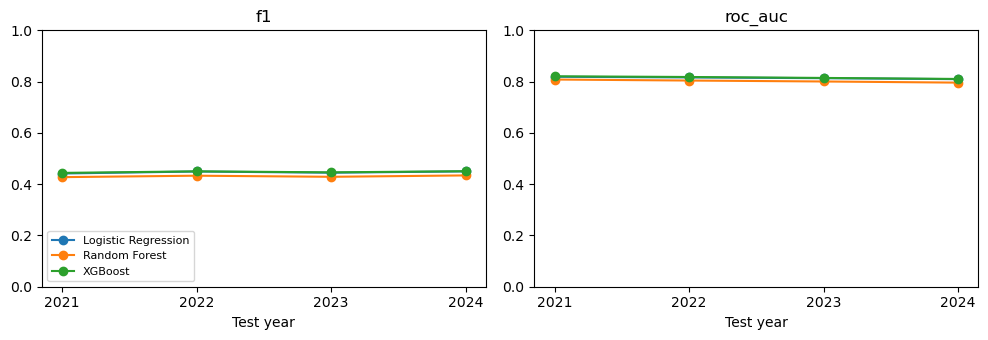

In [31]:
figure, axes = plt.subplots(1, 2, figsize=(10, 3.5))
metrics = ["f1", "roc_auc"]

for axis, metric in zip(axes, metrics):
    for name in models:
        rows = results.loc[results["model"].eq(name)]
        axis.plot(rows["year"], rows[metric], marker="o", label=name)
    axis.set_title(metric)
    axis.set_xticks([2021, 2022, 2023, 2024])
    axis.set_xlabel("Test year")
    axis.set_ylim(0, 1)

axes[0].legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.show()

ROC-AUC decreased slightly from 2021 to 2024 for all three models. For XGBoost, it changed from 0.8208 to 0.8104. F1 stayed within a small range and was slightly higher in 2024 than in 2021. Recall also increased slightly, as shown in the score table. These measures changed in different ways.